# Mixed-mode delamination of AS4D/PEKK-FC with fibre bridging: DCB and MMB tests of Tijs et al.

B. H. A. H. Tijs, S. Abdel-Monsef, J. Renart, A. Turon and C. Bisagni, *Characterization and analysis of the interlaminar behavior of thermoplastic composites considering fiber bridging and R-curve effects*, Compos. Part A 2022; 162:107101, https://doi.org/10.1016/j.compositesa.2022.107101.

S. Abdel-Monsef, B. H. A. H. Tijs, J. Renart and A. Turon, *Accurate simulation of delamination under mixed-mode loading using a multilinear cohesive law*, Eng. Fract. Mech. 2023; 284:109233, https://doi.org/10.1016/j.engfracmech.2023.109233.

Cohesive laws: I. Leciñana, J. Renart, A. Turon, J. Zurbitu and B. H. A. H. Tijs, *Characterization and analysis of the mode I interlaminar fatigue behaviour of thermoplastic composites considering R-curve effects*, Eng. Fract. Mech. 2023; 286:109273, https://doi.org/10.1016/j.engfracmech.2023.109273.

Unidirectional AS4D/PEKK-FC specimens tested by Tijs et al. (2022) in the double cantilever beam (DCB, initial crack lengths $a_0$ = 48 and 40 mm) and in the mixed-mode bending (MMB) test at $G_{II}/G$ = 50% ($a_0$ = 40 mm). In mode I the material has a strong R-curve from fibre bridging: the toughness grows from 0.70 N/mm at initiation to 1.12 N/mm in propagation (Tijs et al. 2022, p. 8). No bridging was observed in the MMB test (Tijs et al. 2022, p. 12). Leciñana et al. (2023) represent the mode I law by five superposed bilinear laws, two for the crack tip and three for the bridging in the wake. Abdel-Monsef et al. (2023) analysed both tests with a multilinear cohesive law in ABAQUS.

`panels` models the three tests with the coupons of `panels.multidomain.delamination.create_coupon` (CLPT and FSDT arms), the interface being the five superposed laws of Leciñana et al. (2023) with a mixed-mode rule fixed before the analyses (theory: [mixed-mode cohesive zone](../cohesive_zone_mixed_mode.rst)). The three bridging laws have no shear stiffness: they are driven by the opening alone and dissipate their mode I toughness on any path. A single bilinear law with the propagation toughness is run for comparison, and linear elastic fracture mechanics (LEFM), the corrected beam theory of ASTM D6671/D6671M-22, is computed as a further reference. The mode I tests of the same material are also in the notebooks [dcb_tijs2022](dcb_tijs2022.ipynb) and [dcb_lecinana2023](dcb_lecinana2023.ipynb).

In [1]:
%matplotlib inline
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, os.path.abspath('.'))
import mmb_utils as mu
from panels.multidomain.connections.czm import BilinearLaw, law_with_ratio

# True runs panels and saves the results in RESULTS, False loads them
RERUN = bool(int(os.environ.get('MMB_RERUN', '0')))
RESULTS = 'results'
REFERENCE = os.path.join('reference_data', 'case3_as4dpekk')
# comma-separated keys, e.g. MMB50_clpt_multilinear, runs only these (used to run in parallel)
ONLY = os.environ.get('MMB_TESTS')
ONLY = ONLY.split(',') if ONLY else None

## Specimen and material data

- Ply properties, Tijs et al. (2022), Table 1, p. 3: $E_{11}$ = 133.15 GPa and $E_{22}$ = 10.95 GPa, the averages of the tensile and compressive moduli (138.3/128.0 and 10.4/11.5 GPa) as used by Tijs et al. (2022), p. 14, and by Abdel-Monsef et al. (2023), Table 2, p. 8; $G_{12} = G_{13}$ = 5.19 GPa, $\nu_{12}$ = 0.316. $G_{23}$ = 3.5 GPa is from Abdel-Monsef et al. (2023), Table 2, the only source.
- Specimen, Tijs et al. (2022), p. 2 and Table 2, p. 13: width 25 mm, 30 plies of 0.14 mm, i.e. arms of $h$ = 2.1 mm; length 225 mm.
- DCB: $a_0$ = 48 mm (University of Girona test, ISO 15024; p. 3 and Fig. 12) and $a_0$ = 40 mm (TU Delft tests, ASTM D5528; p. 3 and Table 2), both from the insert. The DCB has the slope of the upper arm zero at the far end, 225 mm from the load line.
- MMB at 50%, p. 5 and Table 2: $a_0$ = 40 mm after a mode I precrack of "a few millimeter" (the actual precrack length is not given), half-span $L$ = 65 mm, lever length $c$ = 54.4 mm. The weight of the lever, 9.129 N with its centre of gravity at 12.95 mm (p. 5), is included in LEFM below and not modelled in `panels`.

In [2]:
laminaprop = (133150., 10950., 0.316, 5190., 5190., 3500.)   # E11, E22, nu12, G12, G13, G23
plyt, stack = 0.14, [0]*15                                   # arm: 15 plies, h = 2.1 mm
b, x_end = 25., 225.
P_g, c_g = 9.129, 12.95                                      # lever weight and its lever arm (MMB)

# B = G_II/G (nominal), a0, L, c; delta_max: last load-point displacement of the runs,
# twice the displacement at the LEFM peak
tests = {
    'DCB48': dict(kind='DCB', B=0.0, a0=48., delta_max=11.8038),
    'DCB40': dict(kind='DCB', B=0.0, a0=40., delta_max=8.4384),
    'MMB50': dict(kind='MMB', B=0.5, a0=40., L=65., c=54.4, delta_max=10.4957),
}

## Cohesive laws

**Mode I.** The five bilinear laws of Leciñana et al. (2023), Table 2, p. 7: CL1 and CL2, the strongest, represent the crack tip, CL3-CL5 the fibre bridging. Their toughnesses add up to the propagation toughness of the DCB tests, $G_{Ic}$ = 1.12 N/mm (Tijs et al. 2022, p. 8, Figs. 12b and 13a), and their strengths to 88.2 MPa.

**Mixed mode.** Leciñana et al. (2023) studied mode I only, and give no shear properties. The rule below was fixed before any MMB analysis, and no input was tuned to the MMB test:

- the crack-tip laws share the mode II toughness of Tijs et al. (2022), $G_{IIc}$ = 2.35 N/mm (pp. 10-11, Figs. 17-21), in proportion to their mode I toughnesses, and have the Benzeggagh-Kenane exponent $\eta$ = 2.9 of Tijs et al. (2022), pp. 12 and 14;
- one ratio $\kappa = k_{sh}/k_I$ for the crack-tip laws gives CL1 the shear strength of the material, 60 MPa (Tijs et al. 2022, Table 1, p. 3, and p. 14), through the consistency condition $G_{Ic}/G_{oI} = G_{IIc}/G_{oII}$ (`law_with_ratio`);
- the bridging laws have no mode II toughness. As first fixed, the rule gave them the same ratio $\kappa$; the first MMB analyses showed this to be ill-posed, since a law without shear toughness loses its bridging, without dissipating energy, as soon as the closed interface ahead of the crack tip slides. The bridging laws were therefore given no shear stiffness, $k_{sh} = 0$, and their damage is driven by the opening alone (`opening_driven=True`, `law_with_ratio(..., shear_free=True)`): they are mode I ligaments that dissipate exactly their $G_{Ic}$ on any path, and keep their full toughness at any mode ratio. This change was not fixed in advance; it changes no other input. The mode-ratio dependence of the interface is carried by the crack-tip laws alone.

**Bilinear law** (comparison): $G_{Ic}$ = 1.12 N/mm, $G_{IIc}$ = 2.35 N/mm, $\eta$ = 2.9, $\tau_I$ = 87 MPa (= $Y_T$, Tijs et al. 2022, Table 1 and p. 14), $\tau_{II}$ = 60 MPa, $k_I = 10^5$ N/mm$^3$ and the consistent shear stiffness.

In [3]:
# Lecinana et al. (2023), Table 2, p. 7: name, tau_I (MPa), K_I (N/mm^3), G_Ic (N/mm)
lec = [('CL1', 62., 1.0e6, 0.28), ('CL2', 20., 4.5e5, 0.25), ('CL3', 5.5, 9.17e4, 0.25),
       ('CL4', 0.5, 1.67e4, 0.10), ('CL5', 0.2, 3.33e3, 0.24)]
GIIc, eta, tauII = 2.35, 2.9, 60.
tip = lec[:2]                                     # crack-tip laws
Gtip = sum(g for *_, g in tip)
GIIc1 = GIIc*tip[0][3]/Gtip
kappa = (tauII/tip[0][1])**2*tip[0][3]/GIIc1      # CL1 gets tau_II = 60 MPa
ml_laws = []
for i, (name, tau, K, G) in enumerate(lec):
    if i < 2:
        ml_laws.append(law_with_ratio(G, GIIc*G/Gtip, tau, K, eta, kappa, name=name))
    else:
        ml_laws.append(law_with_ratio(G, 0., tau, K, eta, kappa, name=name,
                                      opening_driven=True, shear_free=True))
bl_law = BilinearLaw(1.12, 2.35, 87., 60., 1.e5, 2.9)

rows = ['| law | $\\tau_I$ (MPa) | $k_I$ (N/mm$^3$) | $G_{Ic}$ (N/mm) | $G_{IIc}$ (N/mm) | $\\tau_{II}$ (MPa) '
        '| $k_{sh}$ (N/mm$^3$) | role |', '|---|---|---|---|---|---|---|---|']
for l in ml_laws + [bl_law]:
    rows.append('| {0} | {1:g} | {2:.4g} | {3:g} | {4:.4f} | {5:.2f} | {6:.4g} | {7} |'.format(
        l.name or 'bilinear', l.tauI, l.KI, l.GIc, l.GIIc, l.tauII, l.KII,
        'bridging, opening-driven' if l.opening_driven else
        ('crack tip' if l.name else 'single law (comparison)')))
rows.append('| sum CL1-CL5 | {0:g} | {1:.4g} | {2:g} | {3:g} | | {4:.4g} | |'.format(
    sum(l.tauI for l in ml_laws), sum(l.KI for l in ml_laws), sum(l.GIc for l in ml_laws),
    sum(l.GIIc for l in ml_laws), sum(l.KII for l in ml_laws)))
print('kappa = {0:.4f}'.format(kappa))
display(Markdown('\n'.join(rows)))

kappa = 0.2112


| law | $\tau_I$ (MPa) | $k_I$ (N/mm$^3$) | $G_{Ic}$ (N/mm) | $G_{IIc}$ (N/mm) | $\tau_{II}$ (MPa) | $k_{sh}$ (N/mm$^3$) | role |
|---|---|---|---|---|---|---|---|
| CL1 | 62 | 1e+06 | 0.28 | 1.2415 | 60.00 | 2.112e+05 | crack tip |
| CL2 | 20 | 4.5e+05 | 0.25 | 1.1085 | 19.35 | 9.505e+04 | crack tip |
| CL3 | 5.5 | 9.17e+04 | 0.25 | 0.0000 | 0.00 | 0 | bridging, opening-driven |
| CL4 | 0.5 | 1.67e+04 | 0.1 | 0.0000 | 0.00 | 0 | bridging, opening-driven |
| CL5 | 0.2 | 3330 | 0.24 | 0.0000 | 0.00 | 0 | bridging, opening-driven |
| bilinear | 87 | 1e+05 | 1.12 | 2.3500 | 60.00 | 2.267e+04 | single law (comparison) |
| sum CL1-CL5 | 88.2 | 1.562e+06 | 1.12 | 2.35 | | 3.063e+05 | |

The shapes of the laws in pure mode I and in pure mode II, against the tabular laws of Tijs et al. (2022), Fig. 24, p. 14 ($B$ = 0 and 1; read from the vector drawing, the plotted zero lies 0.024 MPa below the axis and is kept as read). The superposed law and the tabular law of Tijs et al. (2022) have the same mode I toughness but are different laws: the tail of the superposed law reaches 2.4 mm, that of Fig. 24 1.5 mm. In mode II only the crack-tip laws carry traction.

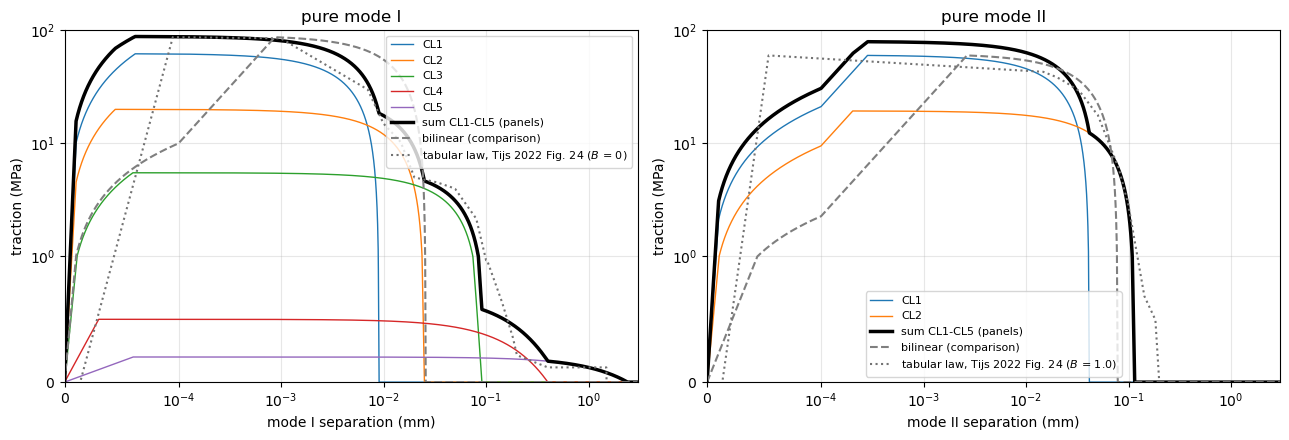

mode I: area under the sum of the laws 1.1200 N/mm
mode II: area under the sum of the laws 2.3500 N/mm


In [4]:
def bilinear_traction(law, s, mode='I'):
    """Traction of a bilinear law under a monotonic pure-mode separation s"""
    K, tau, G = (law.KI, law.tauI, law.GIc) if mode == 'I' else (law.KII, law.tauII, law.GIIc)
    if K == 0. or G == 0.:
        return np.zeros_like(s)
    so, sf = tau/K, 2*G/tau
    return np.where(s <= so, K*s, np.clip(tau*(sf - s)/(sf - so), 0., None))


s = np.r_[0., np.logspace(-5, np.log10(3.), 3000)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, mode, B in ((axes[0], 'I', '0'), (axes[1], 'II', '1.0')):
    tot = np.zeros_like(s)
    for i, l in enumerate(ml_laws):
        t = bilinear_traction(l, s, mode)
        tot += t
        if t.any():
            ax.plot(s, t, lw=1, color='C{0}'.format(i), label=l.name)
    ax.plot(s, tot, lw=2.5, color='k', label='sum CL1-CL5 (panels)')
    ax.plot(s, bilinear_traction(bl_law, s, mode), lw=1.5, ls='--', color='C7', label='bilinear (comparison)')
    t22 = np.loadtxt(os.path.join(REFERENCE, 'Tijs2022_Fig24_CL_B{0}.csv'.format(B)), delimiter=',', skiprows=1)
    ax.plot(t22[:, 0], t22[:, 1], color='0.45', lw=1.5, ls=':', label='tabular law, Tijs 2022 Fig. 24 ($B$ = {0})'.format(B))
    ax.set_xscale('symlog', linthresh=1e-4)
    ax.set_xlim(0, 3.)
    ax.set_yscale('symlog', linthresh=1.)
    ax.set_ylim(0, 100.)
    ax.set_xlabel('mode {0} separation (mm)'.format(mode))
    ax.set_ylabel('traction (MPa)')
    ax.set_title('pure mode {0}'.format(mode))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for mode in ('I', 'II'):
    area = np.trapezoid(sum(bilinear_traction(l, s, mode) for l in ml_laws), s)
    print('mode {0}: area under the sum of the laws {1:.4f} N/mm'.format(mode, area))

## Reference data

**Tests**, Tijs et al. (2022), read from the vector drawings of the figures (< 0.01 mm, 0.01 N):

- DCB, $a_0$ = 48 mm, Fig. 12a, p. 9: one University of Girona test with two records, the loading from the insert, peak 142.4 N at 6.02 mm, and the reloading after the first propagation, peak 140.1 N at 6.72 mm, which then propagates to 24 mm. Unloading branches are not shown. No test curve of the DCB with $a_0$ = 40 mm is used (Fig. 15a, not digitised).
- MMB at 50%, Fig. 22a, p. 12: three tests, peaks 364.1 N (the test drawn with a thick line), 373.2 and 335.1 N; which specimen is which is not stated. The paper does not tabulate the peak loads; the values are the maxima of the digitised curves (point lists of the same drawings in the study notes: 372.8 and 334.9 N for the thin lines).

**FE analyses** of Abdel-Monsef et al. (2023), with their multilinear cohesive law (MLCL) in ABAQUS:

- DCB, $a_0$ = 48 mm, Fig. 12, p. 9 (vector drawing): the MLCL with the fibre-bridging segment ("case 2", peak 141.4 N) and without it ("case 1"), p. 9;
- MMB at 50%, Fig. 14, p. 10 (raster image, $\pm$0.01 mm, $\pm$1.2 N): the MLCL with equal Benzeggagh-Kenane exponents for the crack-tip and the bridging segments, $\eta_1 = \eta_2$ = 2.9 (peak 350.0 N), and the best fit to the test, $\eta_1$ = 2.1, $\eta_2$ = 0.005, which removes the bridging at any mode mixity. The five curves of the figure coincide up to about 4.5 mm, where only the latter is visible; the curve with equal exponents starts where it separates from it.

The peaks are the maxima of the digitised curves; neither paper tabulates them.

In [5]:
TEST = 'Test (Tijs 2022)'   # reference of the differences: DCB48 the loading from the insert, MMB50 the mean of the three tests
ref_peaks = {
    'DCB48': [(TEST, 142.4), ('Test (Tijs 2022), reloading', 140.1),
              ('FE, Abdel-Monsef 2023, MLCL with bridging', None)],
    'DCB40': [],
    'MMB50': [],
}
read = lambda f, **kw: mu.read_curve(os.path.join(REFERENCE, f + '.csv'), **kw)
curves = {
    'DCB48': {'Test (Tijs 2022, Fig. 12a)': read('Tijs2022_Fig12a_DCB_test', loading_only=True) + ('test',)},
    'DCB40': {},
    'MMB50': {},
}
for f in ('AbdelMonsef2023_Fig12_DCB_FEM_MLCL_case2', 'AbdelMonsef2023_Fig12_DCB_FEM_MLCL_case1'):
    d, p = read(f)
    o = np.argsort(d)          # drawn as one stroke per point: sort along the displacement
    lab = 'FE, Abdel-Monsef 2023, MLCL ' + ('with bridging' if f.endswith('2') else 'without bridging')
    curves['DCB48'][lab] = (d[o], p[o], 'FE')
ref_peaks['DCB48'][2] = (ref_peaks['DCB48'][2][0], float(curves['DCB48'][ref_peaks['DCB48'][2][0]][1].max()))
mmb_tests = []
for i, f in enumerate(('highlighted', 'other0', 'other1')):
    d, p = read('Tijs2022_Fig22a_MMB50_test_' + f, loading_only=True)
    curves['MMB50']['Test (Tijs 2022, Fig. 22a)' + ' '*i] = (d, p, 'test')
    mmb_tests.append(float(np.nanmax(p)))
ref_peaks['MMB50'] += [(TEST, float(np.mean(mmb_tests)))] + [
    ('Test (Tijs 2022), {0}'.format(s), p) for s, p in zip(('thick line', 'thin line 1', 'thin line 2'), mmb_tests)]
for f, lab in (('eta2.9_2.9_red_dotted', 'FE, Abdel-Monsef 2023, $\\eta_1 = \\eta_2$ = 2.9'),
               ('eta2.1_0.005_green', 'FE, Abdel-Monsef 2023, $\\eta_1$ = 2.1, $\\eta_2$ = 0.005')):
    d, p = read('AbdelMonsef2023_Fig14_MMB50_FE_' + f)
    curves['MMB50'][lab] = (d, p, 'FE')
    ref_peaks['MMB50'].append((lab.replace('$\\eta_1 = \\eta_2$', 'eta1 = eta2').replace('$\\eta_1$', 'eta1')
                               .replace('$\\eta_2$', 'eta2'), float(np.nanmax(p))))
for k, v in ref_peaks.items():
    for s, p in v:
        print('{0}: {1}: {2:.1f} N'.format(k, s, p))

DCB48: Test (Tijs 2022): 142.4 N
DCB48: Test (Tijs 2022), reloading: 140.1 N
DCB48: FE, Abdel-Monsef 2023, MLCL with bridging: 141.4 N
MMB50: Test (Tijs 2022): 357.5 N
MMB50: Test (Tijs 2022), thick line: 364.1 N
MMB50: Test (Tijs 2022), thin line 1: 373.2 N
MMB50: Test (Tijs 2022), thin line 2: 335.1 N
MMB50: FE, Abdel-Monsef 2023, eta1 = eta2 = 2.9: 350.0 N
MMB50: FE, Abdel-Monsef 2023, eta1 = 2.1, eta2 = 0.005: 356.5 N


## Linear elastic fracture mechanics

Corrected beam theory of ASTM D6671/D6671M-22 (`mmb_utils.lefm_curve`): the compliance of Eq. 10 and the energy release rates of Eqs. 12-13 with the crack length correction $\chi h$ (mode I) and $0.42\chi h$ (mode II), for the MMB with the lever weight (Eqs. 17-18); the DCB is the mode I part of these equations. Self-similar growth at the propagation toughness, $G_{Ic}$ = 1.12 N/mm for the DCB and the Benzeggagh-Kenane value $G_c$(0.5) = 1.285 N/mm for the MMB, up to $a = L$. With its constant toughness, LEFM has no R-curve: it is the reference of the bilinear law, not of the tests.

In [6]:
E11, E22, _, _, G13, _ = laminaprop
h = plyt*len(stack)
x_ = mu.chi(E11, E22, G13)
print('chi = {0:.3f}, chi h = {1:.3f} mm'.format(x_, x_*h))
lefm = {}
for key, t in tests.items():
    Gc = mu.bk(1.12, 2.35, 2.9, t['B'])
    if t['kind'] == 'MMB':
        lefm[key] = mu.lefm_curve('MMB', E11, E22, G13, b, h, t['a0'], Gc, L=t['L'], c=t['c'], P_g=P_g, c_g=c_g)
        P0 = mu.lefm_curve('MMB', E11, E22, G13, b, h, t['a0'], Gc, L=t['L'], c=t['c'])[1].max()
        print('{0}: G_c = {1:.4f} N/mm; lever length of D6671 Eq. 5: {2:.2f} mm (test: {3} mm); '
              'peak {4:.1f} N with the lever weight, {5:.1f} N without'.format(
                  key, Gc, mu.lever_length(t['B'], t['a0'], h, x_, t['L']), t['c'], lefm[key][1].max(), P0))
    else:
        lefm[key] = mu.lefm_curve('DCB', E11, E22, G13, b, h, t['a0'], Gc)
        print('{0}: G_c = {1:.4f} N/mm; peak {2:.1f} N at {3:.2f} mm'.format(
            key, Gc, lefm[key][1].max(), lefm[key][0][np.argmax(lefm[key][1])]))

chi = 1.802, chi h = 3.784 mm
DCB48: G_c = 1.1200 N/mm; peak 163.8 N at 5.90 mm
DCB40: G_c = 1.1200 N/mm; peak 193.7 N at 4.22 mm
MMB50: G_c = 1.2848 N/mm; lever length of D6671 Eq. 5: 54.41 mm (test: 54.4 mm); peak 386.6 N with the lever weight, 388.4 N without


## panels model

Coupons of `create_coupon` (see its docstring for the supports, the lever and the load): each arm is a cracked domain, cohesive domains over 40 mm from the crack tip and, where the bonded length is longer, a far domain with the same cohesive laws; contact over the pre-crack; domains joined with the null-space method. The lever constraint of the MMB acts on the mean deflections across the width; the lever weight is not modelled. The crack length is measured where the crack-tip laws CL1 and CL2 have failed across the width (`tip_laws`); the bridging laws still carry traction behind it.

Discretisation, as in the study of the mixed-mode cohesive model (rules in `mmb_utils.discretisation`):

- superposed laws: 7 cohesive domains of 5.71 mm; $m$ = 22 terms along $x$ for CLPT arms, $1.25\,r L_{dom}$ with $r = \max(\lambda_I, \mu)$ = 2.96 mm$^{-1}$ the decay rate of the sliding of the stiffnesses summed over the laws, and $m$ = 25 for FSDT arms, whose fast decay rate of the opening is 18.5 mm$^{-1}$; 143 Gauss points along $x$ per cohesive domain (25 per mm, about 18 per cohesive zone length of CL1, $0.88 E_{22} G_{Ic}/\tau_I^2$ = 0.70 mm);
- bilinear law: 2 cohesive domains of 20 mm, $m$ = 21 (CLPT) and 25 (FSDT), 500 Gauss points per domain;
- 6 Gauss points and $n = 4$ terms across the width; 10 terms along $x$ in the cracked and far domains.

Solver (`solve_coupon`): Newton-Raphson under displacement control, increments of 0.1 mm (the largest; cut automatically down to $10^{-5}$ mm), relative tolerance $10^{-9}$, up to twice the displacement at the LEFM peak. The peak loads are taken before the crack reaches the saddle, $a < L$. The runs use `mmb_utils.run_or_load_laws`, which also records the energy dissipated by each law (see the section on the bridging below). The table at the end gives the run times and the computers.

In [7]:
L_coh = 40.
disc = {('multilinear', m): mu.discretisation(laminaprop, h, ml_laws, L_coh, 7, model=m, nr_x_gauss=143)
        for m in ('clpt', 'fsdt')}
disc.update({('bilinear', m): mu.discretisation(laminaprop, h, [bl_law], L_coh, 2, model=m, nr_x_gauss=500)
             for m in ('clpt', 'fsdt')})
for k, v in disc.items():
    print(k, {kk: round(vv, 3) if isinstance(vv, float) else vv for kk, vv in v.items()})


def inputs_of(key, model, law):
    t = tests[key]
    dd = disc[(law, model)]
    inp = dict(kind=t['kind'], laminaprop=laminaprop, plyt=plyt, stack=stack, b=b, a0=t['a0'],
               laws=[mu.law_dict(l) for l in (ml_laws if law == 'multilinear' else [bl_law])],
               model=model, nd=dd['nd'], L_coh=L_coh, m_crack=10, m_coh=dd['m_coh'], m_far=10, n=4,
               nr_x_gauss=dd['nr_x_gauss'], nr_y_gauss=6)
    if law == 'multilinear':
        inp['tip_laws'] = [0, 1]
    if t['kind'] == 'DCB':
        inp['x_end'] = x_end
    else:
        inp['L'], inp['c'] = t['L'], t['c']
    return inp


def solver_of(key):
    return dict(delta_max=tests[key]['delta_max'], inc=0.1, min_inc=1e-5, relTOL=1e-9)


runs = {}
for key in tests:
    for law in ('multilinear', 'bilinear'):
        if law == 'bilinear' and key == 'DCB40':
            continue
        for model in ('fsdt', 'clpt'):
            name = '{0}_{1}_{2}'.format(key, model, law)
            if ONLY is not None and name not in ONLY:
                continue
            path = os.path.join(RESULTS, 'mmb_tijs2022_as4dpekk_{0}.npz'.format(name))
            runs[name] = mu.run_or_load_laws(inputs_of(key, model, law), solver_of(key), path, rerun=RERUN)

('multilinear', 'clpt') {'lambda_I': 1.66, 'mu': 2.96, 'r_fast_fsdt': 0.0, 'l_cz': 0.702, 'L_dom': 5.714, 'nd': 7, 'm_coh': 22, 'nr_x_gauss': 143}
('multilinear', 'fsdt') {'lambda_I': 1.66, 'mu': 2.96, 'r_fast_fsdt': 18.544, 'l_cz': 0.702, 'L_dom': 5.714, 'nd': 7, 'm_coh': 25, 'nr_x_gauss': 143}
('bilinear', 'clpt') {'lambda_I': 0.835, 'mu': 0.805, 'r_fast_fsdt': 0.0, 'l_cz': 1.426, 'L_dom': 20.0, 'nd': 2, 'm_coh': 21, 'nr_x_gauss': 500}
('bilinear', 'fsdt') {'lambda_I': 0.835, 'mu': 0.805, 'r_fast_fsdt': 4.69, 'l_cz': 1.426, 'L_dom': 20.0, 'nd': 2, 'm_coh': 25, 'nr_x_gauss': 500}


## Results

Peak loads: references, LEFM and `panels`; the differences are to the test (DCB, $a_0$ = 48 mm: the loading from the insert; MMB: the mean of the three tests).

In [8]:
rows = []
for key, t in tests.items():
    for s, p in ref_peaks[key]:
        rows.append((key, s, p))
    rows.append((key, 'LEFM (ASTM D6671), $G_c$ of propagation', float(lefm[key][1].max())))
    for law in ('multilinear', 'bilinear'):
        for model in ('fsdt', 'clpt'):
            res = runs.get('{0}_{1}_{2}'.format(key, model, law))
            if res is not None:
                rows.append((key, 'panels {0}, {1}'.format(model.upper(), 'CL1-CL5' if law == 'multilinear'
                                                           else 'bilinear law'), mu.peak_load(res, t.get('L'))[0]))
display(Markdown(mu.peaks_table(rows, ref=TEST)))

| test | source | $P_{max}$ (N) | vs Test (Tijs 2022) |
|---|---|---|---|
| DCB48 | Test (Tijs 2022) | 142.4 | - |
| DCB48 | Test (Tijs 2022), reloading | 140.1 | -1.6% |
| DCB48 | FE, Abdel-Monsef 2023, MLCL with bridging | 141.4 | -0.7% |
| DCB48 | LEFM (ASTM D6671), $G_c$ of propagation | 163.8 | +15.0% |
| DCB48 | panels FSDT, CL1-CL5 | 134.4 | -5.6% |
| DCB48 | panels CLPT, CL1-CL5 | 136.9 | -3.9% |
| DCB48 | panels FSDT, bilinear law | 161.2 | +13.2% |
| DCB48 | panels CLPT, bilinear law | 166.1 | +16.6% |
| DCB40 | LEFM (ASTM D6671), $G_c$ of propagation | 193.7 | - |
| DCB40 | panels FSDT, CL1-CL5 | 157.6 | - |
| DCB40 | panels CLPT, CL1-CL5 | 161.0 | - |
| MMB50 | Test (Tijs 2022) | 357.5 | - |
| MMB50 | Test (Tijs 2022), thick line | 364.1 | +1.9% |
| MMB50 | Test (Tijs 2022), thin line 1 | 373.2 | +4.4% |
| MMB50 | Test (Tijs 2022), thin line 2 | 335.1 | -6.3% |
| MMB50 | FE, Abdel-Monsef 2023, eta1 = eta2 = 2.9 | 350.0 | -2.1% |
| MMB50 | FE, Abdel-Monsef 2023, eta1 = 2.1, eta2 = 0.005 | 356.5 | -0.3% |
| MMB50 | LEFM (ASTM D6671), $G_c$ of propagation | 386.6 | +8.2% |
| MMB50 | panels FSDT, CL1-CL5 | 363.7 | +1.7% |
| MMB50 | panels CLPT, CL1-CL5 | 368.6 | +3.1% |
| MMB50 | panels FSDT, bilinear law | 389.9 | +9.1% |
| MMB50 | panels CLPT, bilinear law | 393.9 | +10.2% |

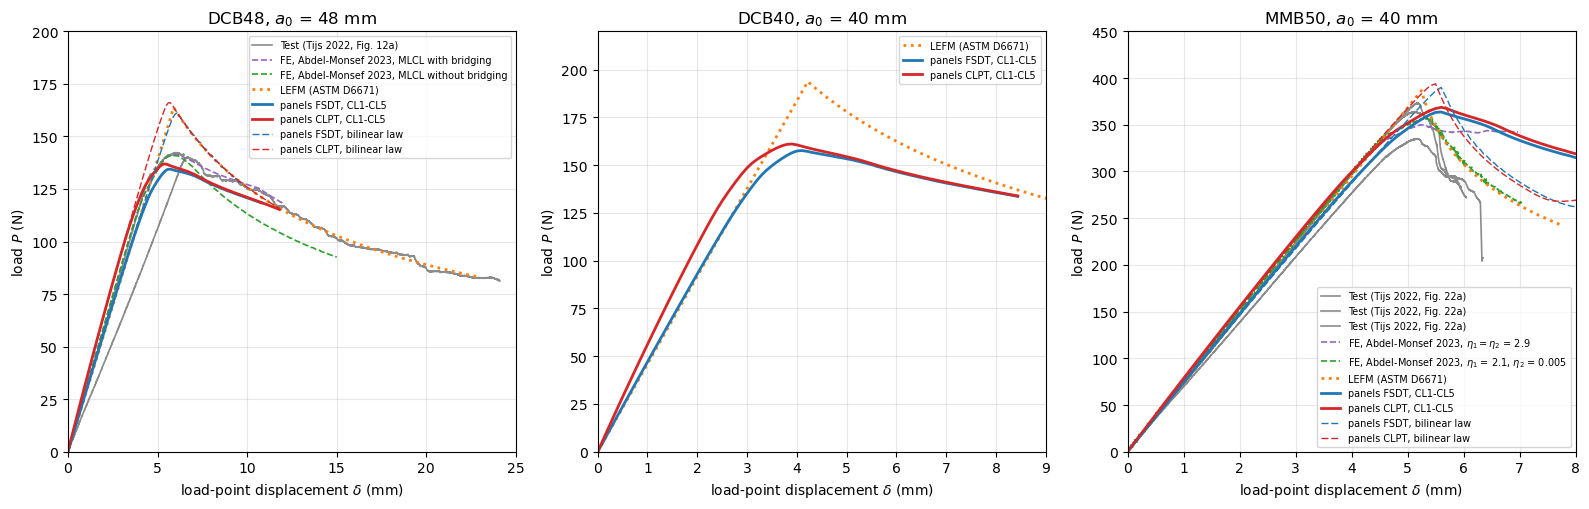

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
style = {'test': dict(color='0.55', lw=1.2), 'FE': dict(lw=1.2, ls='--')}
fe_colour = {'with bridging': 'C4', 'without bridging': 'C2', '2.9': 'C4', '0.005': 'C2'}
for ax, (key, t) in zip(axes, tests.items()):
    cs = {}
    for label, (d, p, kind) in curves[key].items():
        kw = dict(style[kind])
        if kind == 'FE':
            kw['color'] = next(c for k, c in fe_colour.items() if label.rstrip('$').endswith(k))
        cs[label] = (d, p, kw)
    cs['LEFM (ASTM D6671)'] = (lefm[key][0], lefm[key][1], dict(color='C1', ls=':', lw=2))
    for law in ('multilinear', 'bilinear'):
        for model, col in (('fsdt', 'C0'), ('clpt', 'C3')):
            res = runs.get('{0}_{1}_{2}'.format(key, model, law))
            if res is not None:
                lab = 'panels {0}, {1}'.format(model.upper(), 'CL1-CL5' if law == 'multilinear' else 'bilinear law')
                cs[lab] = (np.r_[0., res['delta']], np.r_[0., res['P']],
                           dict(color=col, lw=2 if law == 'multilinear' else 1,
                                ls='-' if law == 'multilinear' else (0, (5, 2))))
    mu.plot_test(ax, cs, title='{0}, $a_0$ = {1:g} mm'.format(key, t['a0']))
    ax.set_xlim(0, {'DCB48': 25., 'DCB40': 9., 'MMB50': 8.}[key])
    ax.set_ylim(0, {'DCB48': 200., 'DCB40': 220., 'MMB50': 450.}[key])
    ax.legend(fontsize=7, loc='lower right' if key == 'MMB50' else 'upper right')
plt.tight_layout()
plt.show()

## Fibre bridging in the analyses

Energy dissipated by each of the five laws along the analyses with CLPT arms, from `mmb_utils.solve_laws`: the split per law of the dissipation of the interface, $\sum_g w_g \sum_k G_c^{[\ell]}(B)\,\Delta r^{[\ell]}$. For the bridging laws, which have no shear stiffness, this is exactly the energy they dissipate; for the crack-tip laws it is the dissipation of the mixed-mode law. The dashed line marks the peak load.

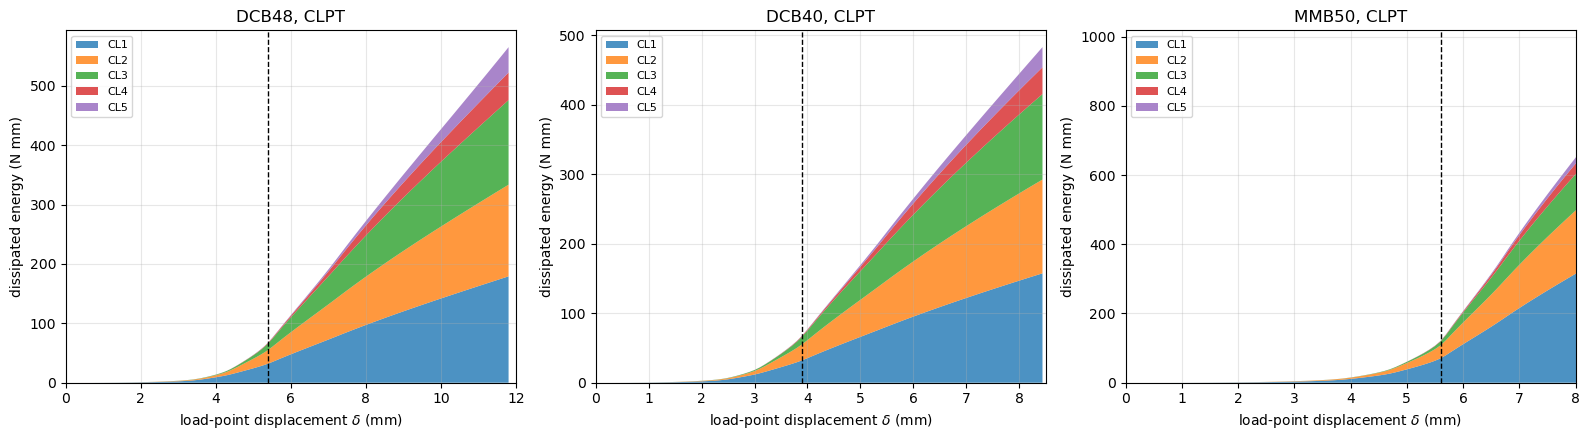

| test | arms | state | $\delta$ (mm) | $a - a_0$ (mm) | CL1 | CL2 | CL3 | CL4 | CL5 | total (N mm) | bridging share |
|---|---|---|---|---|---|---|---|---|---|---|---|
| DCB48 | CLPT | peak | 5.40 | 2.1 | 32.4 | 23.3 | 11.2 | 1.0 | 0.4 | 68.3 | 19% |
| DCB48 | CLPT | last | 11.80 | 23.0 | 179.2 | 154.4 | 142.5 | 46.4 | 42.7 | 565.2 | 41% |
| DCB48 | FSDT | peak | 5.70 | 1.9 | 24.1 | 18.6 | 10.4 | 1.0 | 0.4 | 54.5 | 22% |
| DCB48 | FSDT | last | 10.82 | 18.6 | 141.5 | 123.4 | 115.3 | 37.1 | 28.6 | 445.9 | 41% |
| DCB40 | CLPT | peak | 3.90 | 2.1 | 32.3 | 23.2 | 11.1 | 1.0 | 0.4 | 68.0 | 18% |
| DCB40 | CLPT | last | 8.44 | 19.9 | 157.4 | 135.0 | 123.0 | 38.6 | 29.0 | 483.1 | 39% |
| DCB40 | FSDT | peak | 4.10 | 1.7 | 22.5 | 17.2 | 9.0 | 0.8 | 0.3 | 49.9 | 20% |
| DCB40 | FSDT | last | 8.44 | 18.4 | 140.0 | 122.1 | 114.0 | 36.5 | 27.4 | 440.0 | 40% |
| MMB50 | CLPT | peak | 5.60 | 2.4 | 70.4 | 37.6 | 11.4 | 1.0 | 0.4 | 120.8 | 11% |
| MMB50 | CLPT | $\delta$ = 6 mm | 6.00 | 5.2 | 111.2 | 62.5 | 28.5 | 3.2 | 1.3 | 206.7 | 16% |
| MMB50 | FSDT | peak | 5.60 | 2.1 | 52.3 | 28.9 | 10.7 | 1.0 | 0.4 | 93.2 | 13% |
| MMB50 | FSDT | $\delta$ = 6 mm | 6.00 | 4.9 | 87.9 | 51.5 | 27.9 | 3.4 | 1.4 | 172.2 | 19% |

In [10]:
names = [l.name for l in ml_laws]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (key, t) in zip(axes, tests.items()):
    res = runs.get('{0}_clpt_multilinear'.format(key))
    if res is None:
        continue
    E = np.vstack((np.zeros(5), res['diss_laws']))
    d = np.r_[0., res['delta']]
    ax.stackplot(d, E.T, labels=names, colors=['C{0}'.format(i) for i in range(5)], alpha=0.8)
    ax.axvline(mu.peak_load(res, t.get('L'))[1], color='k', ls='--', lw=1)
    ax.set_xlim(0, {'DCB48': 12., 'DCB40': 8.5, 'MMB50': 8.}[key])
    ax.set_xlabel(r'load-point displacement $\delta$ (mm)')
    ax.set_ylabel('dissipated energy (N mm)')
    ax.set_title('{0}, CLPT'.format(key))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

out = ['| test | arms | state | $\\delta$ (mm) | $a - a_0$ (mm) | ' + ' | '.join(names)
       + ' | total (N mm) | bridging share |', '|---|---|---|---|---|' + '---|'*7]
for key, t in tests.items():
    for model in ('clpt', 'fsdt'):
        res = runs.get('{0}_{1}_multilinear'.format(key, model))
        if res is None:
            continue
        ip = int(np.argmax(np.where(res['a'] < t.get('L', np.inf), res['P'], -np.inf)))
        if key == 'MMB50':
            il = int(np.argmin(abs(res['delta'] - 6.)))
            last = ('$\\delta$ = 6 mm', il)
        else:
            last = ('last', len(res['delta']) - 1)
        for state, i in (('peak', ip), last):
            e = res['diss_laws'][i]
            out.append('| {0} | {1} | {2} | {3:.2f} | {4:.1f} | '.format(
                key, model.upper(), state, res['delta'][i], res['a'][i] - t['a0'])
                + ' | '.join('{0:.1f}'.format(v) for v in e)
                + ' | {0:.1f} | {1:.0f}% |'.format(e.sum(), 100*e[2:].sum()/e.sum()))
display(Markdown('\n'.join(out)))

In steady propagation of the DCB each law would dissipate $b\,G_{Ic}^{[\ell]}$ per unit of crack growth, and the bridging laws would hold $0.59/1.12$ = 53% of the dissipation. The bridging zone, however, needs tens of millimetres of crack growth to develop, which is the R-curve of the material.

The state of the interface at the peak load: the normal traction of each law, mean across the width, along the interface (CLPT arms). The crack tip, where CL1 and CL2 have failed, is at the vertical line; behind it, the bridging laws CL3-CL5 still carry traction.

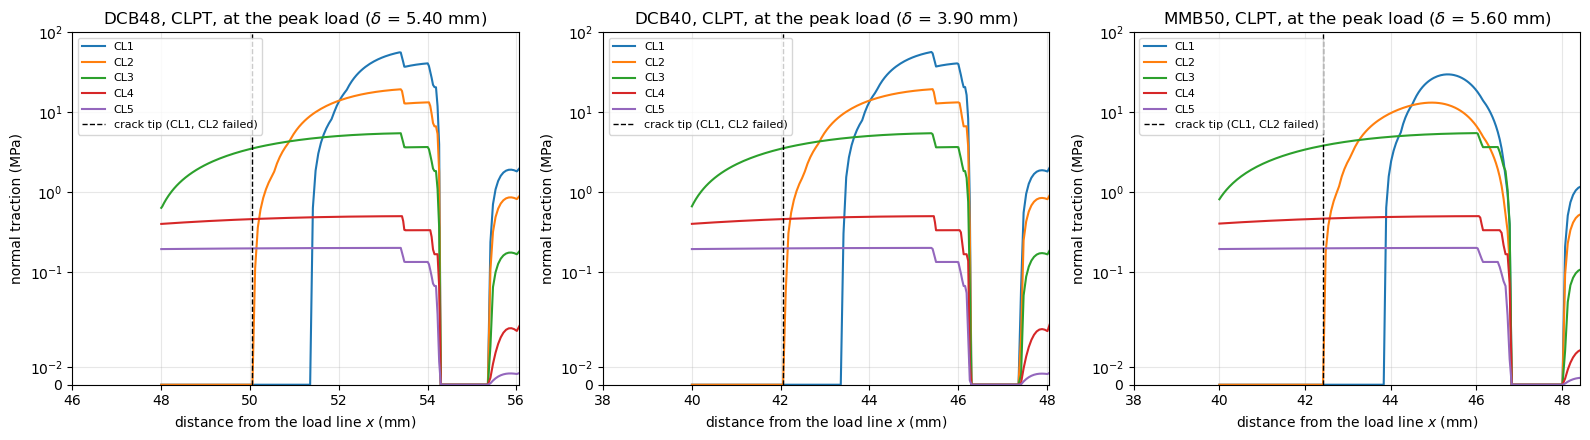

| test | arms | state | $\delta$ (mm) | crack tip $a$ (mm) | CL3 failed up to (mm) | CL4 failed up to (mm) | CL5 failed up to (mm) | bridged length (mm) |
|---|---|---|---|---|---|---|---|---|
| DCB48 | CLPT | peak | 5.40 | 50.1 | 48.0 | 48.0 | 48.0 | 2.1 |
| DCB48 | CLPT | last | 11.80 | 71.0 | 68.2 | 62.0 | 48.0 | 23.0 |
| DCB48 | FSDT | peak | 5.70 | 49.9 | 48.0 | 48.0 | 48.0 | 1.9 |
| DCB48 | FSDT | last | 10.82 | 66.6 | 64.4 | 58.6 | 48.0 | 18.6 |
| DCB40 | CLPT | peak | 3.90 | 42.1 | 40.0 | 40.0 | 40.0 | 2.1 |
| DCB40 | CLPT | last | 8.44 | 59.9 | 57.1 | 50.8 | 40.0 | 19.9 |
| DCB40 | FSDT | peak | 4.10 | 41.7 | 40.0 | 40.0 | 40.0 | 1.7 |
| DCB40 | FSDT | last | 8.44 | 58.4 | 56.2 | 50.4 | 40.0 | 18.4 |
| MMB50 | CLPT | peak | 5.60 | 42.4 | 40.0 | 40.0 | 40.0 | 2.4 |
| MMB50 | CLPT | last | 10.50 | 65.0 | 61.9 | 55.5 | 40.0 | 25.0 |
| MMB50 | FSDT | peak | 5.60 | 42.1 | 40.0 | 40.0 | 40.0 | 2.1 |
| MMB50 | FSDT | last | 10.50 | 64.4 | 62.1 | 56.2 | 40.0 | 24.4 |

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
rows = ['| test | arms | state | $\\delta$ (mm) | crack tip $a$ (mm) | ' + ' | '.join(
        '{0} failed up to (mm)'.format(n) for n in names[2:]) + ' | bridged length (mm) |',
        '|---|---|---|---|---|---|---|---|---|']
for ax, (key, t) in zip(axes, tests.items()):
    for model in ('clpt', 'fsdt'):
        res = runs.get('{0}_{1}_multilinear'.format(key, model))
        if res is None or 'x_peak' not in res:
            continue
        i = int(res['i_peak'])
        # behind the crack tip the bridging laws carry traction up to where CL5, the last, has failed
        for state, j in (('peak', i), ('last', len(res['delta']) - 1)):
            a_l = res['a_laws'][j]
            rows.append('| {0} | {1} | {2} | {3:.2f} | {4:.1f} | {5:.1f} | {6:.1f} | {7:.1f} | {8:.1f} |'.format(
                key, model.upper(), state, res['delta'][j], res['a'][j], *a_l[2:], res['a'][j] - a_l[4]))
        if model != 'clpt':
            continue
        x = res['x_peak']
        for j, n in enumerate(names):
            ax.plot(x, res['tau_peak'][j], color='C{0}'.format(j), lw=1.5, label=n)
        ax.axvline(res['a'][i], color='k', ls='--', lw=1, label='crack tip (CL1, CL2 failed)')
        ax.set_xlim(t['a0'] - 2, res['a'][i] + 6)
        ax.set_yscale('symlog', linthresh=0.05)
        ax.set_ylim(0, 100)
        ax.set_xlabel('distance from the load line $x$ (mm)')
        ax.set_ylabel('normal traction (MPa)')
        ax.set_title('{0}, CLPT, at the peak load ($\\delta$ = {1:.2f} mm)'.format(key, res['delta'][i]))
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()
display(Markdown('\n'.join(rows)))

In [12]:
info = ['| run | status | increments | size | run time (min) | machine |', '|---|---|---|---|---|---|']
for name, res in runs.items():
    info.append('| {0} | {1} | {2} | {3} | {4:.1f} | {5} |'.format(
        name, res['status'], len(res['delta']), res['size'], res['time']/60, res['machine']))
display(Markdown('\n'.join(info)))

| run | status | increments | size | run time (min) | machine |
|---|---|---|---|---|---|
| DCB48_fsdt_multilinear | stopped at delta = 10.8220 | 147 | 7800 | 84.5 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| DCB48_clpt_multilinear | finished | 119 | 4176 | 23.3 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| DCB48_fsdt_bilinear | stopped at delta = 9.7808 | 166 | 2800 | 18.4 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| DCB48_clpt_bilinear | finished | 119 | 1488 | 6.0 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| DCB40_fsdt_multilinear | finished | 125 | 7800 | 74.9 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| DCB40_clpt_multilinear | finished | 85 | 4176 | 17.6 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB50_fsdt_multilinear | finished | 105 | 7800 | 58.4 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB50_clpt_multilinear | finished | 105 | 4176 | 19.2 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB50_fsdt_bilinear | finished | 282 | 2800 | 35.5 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB50_clpt_bilinear | finished | 105 | 1488 | 5.3 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |

## Discussion

- **DCB.** With the five superposed laws the DCB with $a_0$ = 48 mm peaks at 136.9 N (CLPT) and 134.4 N (FSDT), 3.9 and 5.6% below the loading of the test from the insert, 142.4 N, and 3.2 and 4.9% below the FE analysis of Abdel-Monsef et al. (2023), 141.4 N; between $\delta$ = 8 and 11 mm the propagation branch is 2-4% below the test. With $a_0$ = 40 mm the peaks are 161.0 and 157.6 N. The bilinear law with the propagation toughness gives 166.1 N (CLPT) and 161.2 N (FSDT), 13-17% above the test and close to LEFM, 163.8 N: without the R-curve the full propagation toughness acts from the first millimetre of growth.
- **Bridging.** At the DCB peak the crack has grown 2.1 mm and the bridging laws CL3-CL5 hold 18-19% of the dissipated energy with CLPT arms and 20-22% with FSDT arms; after 18-23 mm of growth they hold 39-41%, still below the 53% of steady propagation, and CL5 has not failed anywhere behind the crack tip: the bridging zone still covers the whole crack growth, and the R-curve is still rising, as in the test (Tijs et al. 2022, Figs. 12b and 13a). In the MMB the bridging laws hold 11% (CLPT) and 13% (FSDT) of the dissipation at the peak and 16% and 19% at $\delta$ = 6 mm.
- **MMB at 50%.** The peak is 368.6 N (CLPT) and 363.7 N (FSDT), both at $\delta$ = 5.6 mm after 2.1-2.4 mm of growth, within the scatter of the three tests (335.1-373.2 N), +3.1 and +1.7% from their mean, 357.5 N; the FE analysis of Abdel-Monsef et al. (2023) with equal exponents gives 350.0 N. The bilinear law gives 393.9 and 389.9 N, 9-10% above the mean and above every test. After the peak the tests drop to about 285-292 N at $\delta$ = 6 mm (Fig. 22a), while `panels` stays at 361 N (CLPT) and 356 N (FSDT). Abdel-Monsef et al. (2023) matched the drop only with $\eta_2$ = 0.005, which removes the bridging at any mode mixity. No bridging was observed in the MMB test (Tijs et al. 2022, p. 12), whereas the bridging laws, identified from the DCB, keep their full toughness at any mode ratio: how the bridging depends on the mode ratio cannot be identified from mode I tests alone, and the models predict the peak but not the loss of bridging after it.
- **CLPT and FSDT arms.** The CLPT arms give peaks 1.9-2.2% above the FSDT arms in the DCB and 1.4% in the MMB.
- **Lever weight.** It is not modelled in `panels`; in LEFM it lowers the MMB peak by 0.5% (388.4 to 386.6 N).
- **Study of the mixed-mode model.** The peak loads are those of the runs of the study (tags `multilinear_opn_bG0` and the bilinear runs), to the digits printed.